# SCA13 — MNTB model: checks and Activity A
Run this notebook with any version of the neuron: set `NESTML_FILE` in the first cell (e.g. `hh_neuron_sca13_final.nestml` for Model A, or the recalibrated neuron). Everything else adapts.

Sections:
1. Figure 9 (calibration target) with the loaded neuron.
2. Post-calibration checks: resting potential, current steps, single AP shape, voltage clamp. Original hWang (20/500 nS) and Model A (27/510 nS) are always included for comparison.
3. Figure 1d–f with the experimental pulse (2 nA, 0.3 ms).
4. Activity A (Figure 8): A1 two protocols, A2 amplitude/duration at 400 Hz, A2b other pulse durations, A3 critical frequency, A4 Figure 8 at an intermediate frequency.
5. Summary table, to compare different neurons.

References: Macica et al. 2003 (REF1), Wang et al. 1998 (REF2). Failure = peak below −10 mV (Macica). Run in ataxia_env.

In [17]:
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pickle
import nest
from pathlib import Path
from pynestml.frontend.pynestml_frontend import generate_nest_target

NESTML_FILE = "hh_neuron_sca13_final.nestml"

source = Path(NESTML_FILE).resolve()
assert source.is_file(), source
name = re.search(r"^model\s+(\w+)\s*:", source.read_text(), re.M).group(1)
module_name = name + "_module"
model = name + "_nestml"
target = Path("target_" + name).resolve()
generate_nest_target(input_path=str(source), target_path=str(target), module_name=module_name, suffix="_nestml")
module = target / (module_name + ".so")
assert module.is_file(), module
nest.ResetKernel()
if model not in nest.node_models:
    nest.Install(str(module))
DEFAULTS = nest.GetDefaults(model)
display(pd.Series({k: DEFAULTS[k] for k in ["g_Na","g_LT","g_Kv31","g_L","E_L","E_K","E_Na","C_m"]}, name=name))

results_dir = Path("checks_results_" + name)
results_dir.mkdir(exist_ok=True)
DT, T0, AMP, DUR, AP_THRESHOLD = 0.005, 50., 1400., 0.25, -10.
GRID_ROUNDING = False


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:27:06

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

CMake Warning:
  Ignoring empty string ("") provided on the command line.


-- The CXX compiler identification is GNU 15.3.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /home/ciudo/anaconda3/envs/ataxia_env/bin/x86_64-conda-linux-gnu-c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done

-------------------------------------------------------
hh_neuron_sca13_final_module Configuration Summary
-------------------------------------------------------

C++ compiler         : /home/ciudo/anaconda3/envs/ataxia_env/bin/x86_64-conda-linux-gnu-c++
Build static libs    :

g_Na      510.0
g_LT       27.0
g_Kv31    150.0
g_L         2.0
E_L       -63.0
E_K       -80.0
E_Na       50.0
C_m        10.0
Name: hh_neuron_sca13_final, dtype: float64

In [18]:
def round_time(t):
    return round(round(t / DT) * DT, 6) if GRID_ROUNDING else round(t, 2)

def new_kernel():
    nest.ResetKernel(); nest.set_verbosity("M_ERROR"); nest.SetKernelStatus({"resolution": DT})
    if model not in nest.node_models: nest.Install(str(module))

def run_train(g_kv31, freq, n_pulses, amp=AMP, dur=DUR, params=None):
    new_kernel()
    neuron = nest.Create(model, params={**(params or {}), "g_Kv31": g_kv31})
    mm = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": DT})
    nest.Connect(mm, neuron)
    period = 1000.0 / freq
    starts = [round_time(T0 + k * period) for k in range(n_pulses)]
    times = []; values = []
    for s in starts:
        times += [s, round_time(s + dur)]; values += [amp, 0.0]
    gen = nest.Create("step_current_generator", params={"amplitude_times": times, "amplitude_values": values})
    nest.Connect(gen, neuron, syn_spec={"delay": DT})
    nest.Simulate(round_time(starts[-1] + 40.0))
    ev = mm.get("events"); t = np.array(ev["times"]); V = np.array(ev["V_m"])
    peaks = []; delays = []
    for i, s in enumerate(starts):
        end = starts[i+1] if i+1 < len(starts) else s + period
        window = (t >= s + DT) & (t < end + DT)
        k = np.argmax(V[window]); peaks.append(V[window][k]); delays.append(t[window][k] - s)
    peaks = np.array(peaks)
    return {"t": t, "V": V, "starts": np.array(starts), "peaks": peaks, "delay": np.array(delays), "ok": peaks >= AP_THRESHOLD}

def run_current(params, times, values, T, rec=("V_m",)):
    new_kernel()
    neuron = nest.Create(model, params=params)
    mm = nest.Create("multimeter", params={"record_from": list(rec), "interval": DT}); nest.Connect(mm, neuron)
    if len(times):
        gen = nest.Create("step_current_generator", params={"amplitude_times": [round_time(t) for t in times], "amplitude_values": [float(v) for v in values]})
        nest.Connect(gen, neuron, syn_spec={"delay": DT})
    nest.Simulate(round_time(T))
    ev = mm.get("events"); return {k: np.array(ev[k]) for k in ["times", *rec]}

def vclamp(params, protocol, rec=("I_HT", "I_LT")):
    new_kernel()
    neuron = nest.Create(model, params={**params, "C_m": 1e9, "g_Na": 0.})
    mm = nest.Create("multimeter", params={"record_from": ["V_m", *rec], "interval": DT}); nest.Connect(mm, neuron)
    for v, d in protocol:
        neuron.set({"V_m": float(v)}); nest.Simulate(round_time(d))
    ev = mm.get("events"); return {k: np.array(ev[k]) for k in ["times", "V_m", *rec]}

def count_aps(t, V, t0, t1):
    w = (t >= t0) & (t < t1); v = V[w]
    return int(np.sum((v[1:] >= AP_THRESHOLD) & (v[:-1] < AP_THRESHOLD)))

def ap_shape(t, V, t0):
    w = (t >= t0) & (t <= t0 + 10.); t, V = t[w] - t0, V[w]; k = np.argmax(V); half = V[0] + (V[k] - V[0]) / 2
    above = np.where(V >= half)[0]; dvdt = np.gradient(V, t)
    return dict(Peak=V[k], Time_to_peak=t[k], Half_width=t[above[-1]] - t[above[0]], Max_dVdt=dvdt[:k+1].max())

def plot_delay(ax, r):
    ok = r['ok']; x = np.arange(len(ok)); y = r['delay'].copy(); y[~ok] = np.nan
    ax.plot(x, y, 'k.-', ms=3)
    ax.plot(x[~ok], np.full(np.sum(~ok), 0.3), 'k', marker=r'$\uparrow$', ls='none')
    ax.text(.98, .95, f'{np.sum(~ok)} failures', transform=ax.transAxes, ha='right', va='top')
    ax.set_ylim(0, max(1.5, 1.08 * np.max(y[ok]) if np.any(ok) else 1.5))

def plot_aps(ax, r, f):
    for i, s in enumerate(r['starts']):
        if not r['ok'][i]: continue
        end = r['starts'][i+1] if i+1 < len(r['starts']) else s + 1000 / f
        w = (r['t'] >= s - .2) & (r['t'] < end) & (r['t'] <= s + 2.)
        ax.plot(r['t'][w] - s, r['V'][w], color='black', alpha=.45, lw=.8)
    ax.set(xlim=(-.2, 2), ylim=(-90, 60))
    ax.text(.98, .95, f"{sum(r['ok'])}/{len(r['ok'])} APs", transform=ax.transAxes, ha='right', va='top')

def metrics(results):
    rows = []
    for (cond, f), r in results.items():
        ok = r['ok']; d = r['delay'][ok]; p = r['peaks'][ok]
        rows.append(dict(Condition=cond, Frequency=f, Failures=int(sum(~ok)), Reliability=100*np.mean(ok),
                         Mean_delay=np.mean(d) if len(d) else np.nan, Jitter=np.std(d) if len(d) else np.nan,
                         Mean_peak=np.mean(p) if len(p) else np.nan))
    return pd.DataFrame(rows)

def save(name, fig, results):
    fig.savefig(results_dir / f'{name}.png', dpi=300, bbox_inches='tight')
    df = metrics(results); df.to_csv(results_dir / f'{name}.csv', index=False)
    with open(results_dir / f'{name}.pkl', 'wb') as h: pickle.dump(results, h)
    display(df.round(3)); plt.show()
    return df

def combined_plot(results, conditions, fa, fb, title):
    fig, axes = plt.subplots(len(fa), 4, figsize=(16, 3*len(fa)))
    for i, (f1, f2) in enumerate(zip(fa, fb)):
        for j, cond in enumerate(conditions):
            a, b = axes[i, j], axes[i, j+2]
            plot_delay(a, results[cond, f1]); plot_aps(b, results[cond, f2], f2)
            if j == 0:
                a.set_ylabel(f'{f1} Hz\nDelay (ms)'); b.set_ylabel(f'{f2} Hz\nV (mV)')
            if i == 0:
                a.set_title('a — ' + cond); b.set_title('b — ' + cond)
            if i == len(fa) - 1:
                a.set_xlabel('Stimulus number'); b.set_xlabel('Time from stimulus (ms)')
    ymax = max(ax.get_ylim()[1] for ax in axes[:, :2].flat)
    for ax in axes[:, :2].flat: ax.set_ylim(0, ymax)
    fig.suptitle(title); fig.tight_layout(rect=[0, 0, 1, .96]); return fig

LOADED = {k: float(DEFAULTS[k]) for k in ["g_LT", "g_Na", "E_L"]}
MODELS = {'Original hWang (20/500 nS)': {'g_LT': 20., 'g_Na': 500., 'E_L': -63.},
          'Model A (27/510 nS)': {'g_LT': 27., 'g_Na': 510., 'E_L': -63.}}
if LOADED not in MODELS.values():
    MODELS[f"Loaded ({LOADED['g_LT']:g}/{LOADED['g_Na']:g} nS, E_L {LOADED['E_L']:g})"] = LOADED
LOADED_NAME = [k for k, v in MODELS.items() if v == LOADED][0]
SUMMARY = {}
print(list(MODELS), '| loaded:', LOADED_NAME)

['Original hWang (20/500 nS)', 'Model A (27/510 nS)'] | loaded: Model A (27/510 nS)


## 1. Figure 9 — calibration target
1.4 nA, 0.25 ms; 150 vs 100 nS; 100 ms trains. Paper failures at 300/350/360/410 Hz: 150 nS 0/2/5/≈14; 100 nS 0/0/0/≈14 (read from the figure).

Control (150 nS) | model [0, 2, 5, 13] | paper [0, 2, 5, 14]
Reduced (100 nS) | model [0, 0, 0, 13] | paper [0, 0, 0, 14]


,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,Control (150 nS),100,0,100.000,0.404,0.003,43.247
1,Control (150 nS),300,0,100.000,0.547,0.030,39.564
2,Control (150 nS),350,2,94.286,0.757,0.145,33.051
3,Control (150 nS),360,5,86.111,0.729,0.194,33.811
4,Control (150 nS),410,13,68.293,0.681,0.195,32.157
5,Reduced (100 nS),100,0,100.000,0.404,0.003,43.239
6,Reduced (100 nS),300,0,100.000,0.520,0.023,39.001
7,Reduced (100 nS),350,0,100.000,0.631,0.042,33.190
8,Reduced (100 nS),360,0,100.000,0.691,0.054,29.952
9,Reduced (100 nS),410,13,68.293,0.708,0.176,24.017


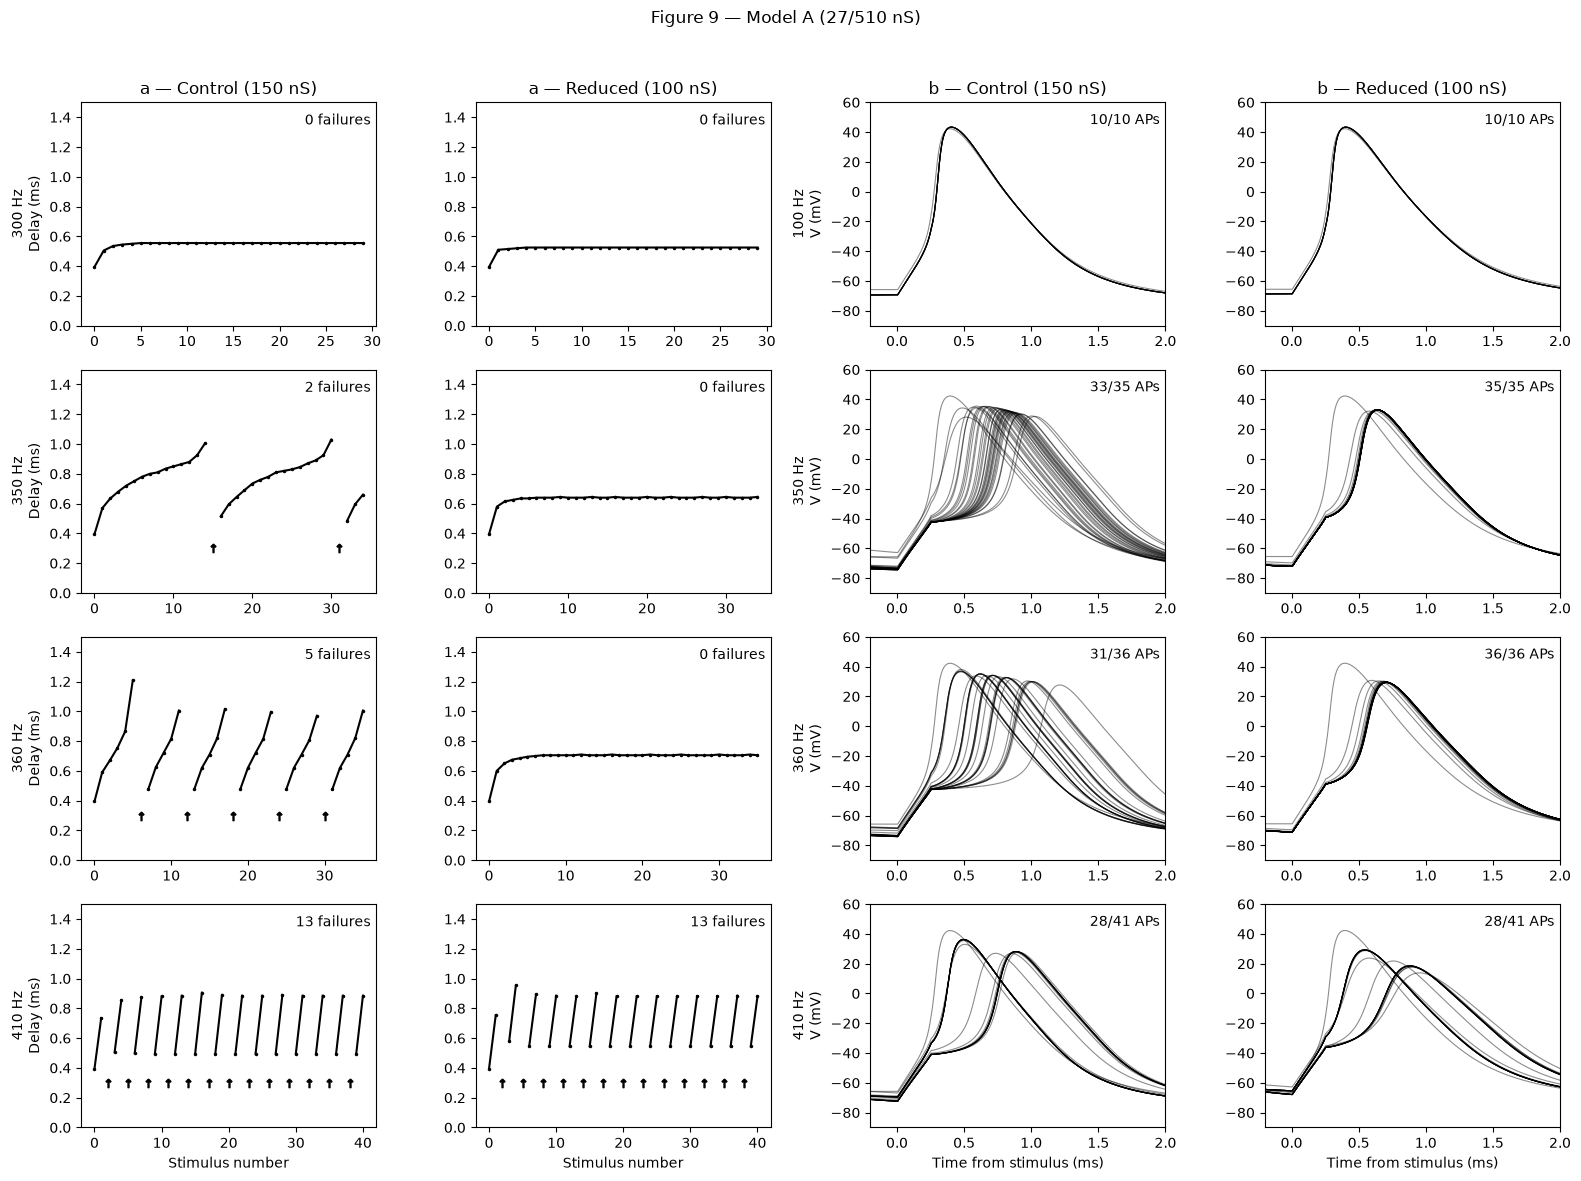

In [19]:
PAPER9 = {'Control (150 nS)': [0, 2, 5, 14], 'Reduced (100 nS)': [0, 0, 0, 14]}
g9 = {'Control (150 nS)': 150., 'Reduced (100 nS)': 100.}
r9 = {(c, f): run_train(g, f, int(f/10)) for c, g in g9.items() for f in [100, 300, 350, 360, 410]}
for c in g9:
    model_f = [int(sum(~r9[c, f]['ok'])) for f in [300, 350, 360, 410]]
    print(c, '| model', model_f, '| paper', PAPER9[c])
    SUMMARY[f'Fig9 failures {c} (300/350/360/410)'] = str(model_f)
fig9 = combined_plot(r9, list(g9), [300, 350, 360, 410], [100, 350, 360, 410], f'Figure 9 — {LOADED_NAME}')
df9 = save('Figure9', fig9, r9)

## 2. Post-calibration checks
### 2.1 Resting potential
Macica: −64.2 ± 1.12 mV (control). Wang Fig. 1A: about −60 mV.

In [20]:
rows = []
for nm, p in MODELS.items():
    ev = run_current(p, [], [], 1000.)
    rows.append(dict(Model=nm, V_rest=ev['V_m'][-1], Drift_last_100ms=ev['V_m'][-1] - ev['V_m'][ev['times'] >= 900.][0]))
rest_df = pd.DataFrame(rows); rest_df.to_csv(results_dir / 'Check_rest.csv', index=False)
SUMMARY['Rest (mV)'] = round(float(rest_df.set_index('Model').loc[LOADED_NAME, 'V_rest']), 2)
display(rest_df.round(3))

,Model,V_rest,Drift_last_100ms
0,Original hWang (20/500 nS),-64.555,-0.0
1,Model A (27/510 nS),-65.739,-0.0


### 2.2 Current steps (Macica Fig. 7b, Wang Fig. 1A and 1D)
150 ms steps from −50 to 400 pA (−100 pA is skipped: it makes the Kv3 p gate very stiff and the simulation extremely slow).
Macica: a single AP at the onset of 50–150 pA steps, then a steady depolarization. Wang: single AP in control, repetitive firing only after DTX (I_LT blocked).
V–I: mean V over the last 20 ms of the step (130–150 ms). Open markers: the neuron fires inside the window, so the mean is not a steady state.

APs                               V_mean_130_150ms  \
Model Model A (27/510 nS) Original hWang (20/500 nS) Model A (27/510 nS)   
I_pA                                                                       
-50                   0.0                        0.0              -87.26   
 0                    0.0                        0.0              -65.74   
 50                  14.0                       15.0              -51.36   
 100                 21.0                       21.0              -46.23   
 150                 24.0                       24.0              -41.90   
 200                  4.0                        4.0              -39.21   
 250                  2.0                        2.0              -36.93   
 300                  2.0                        2.0              -34.98   
 350                  1.0                        1.0              -33.27   
 400                  1.0                        1.0              -31.74   

                                  
Model Original hWang (20/500 nS)  
I_pA                              
-50                       -87.43  
 0                        -64.55  
 50                       -52.00  
 100                      -46.78  
 150                      -40.38  
 200                      -37.39  
 250                      -35.13  
 300                      -33.20  
 350                      -31.50  
 400                      -29.97

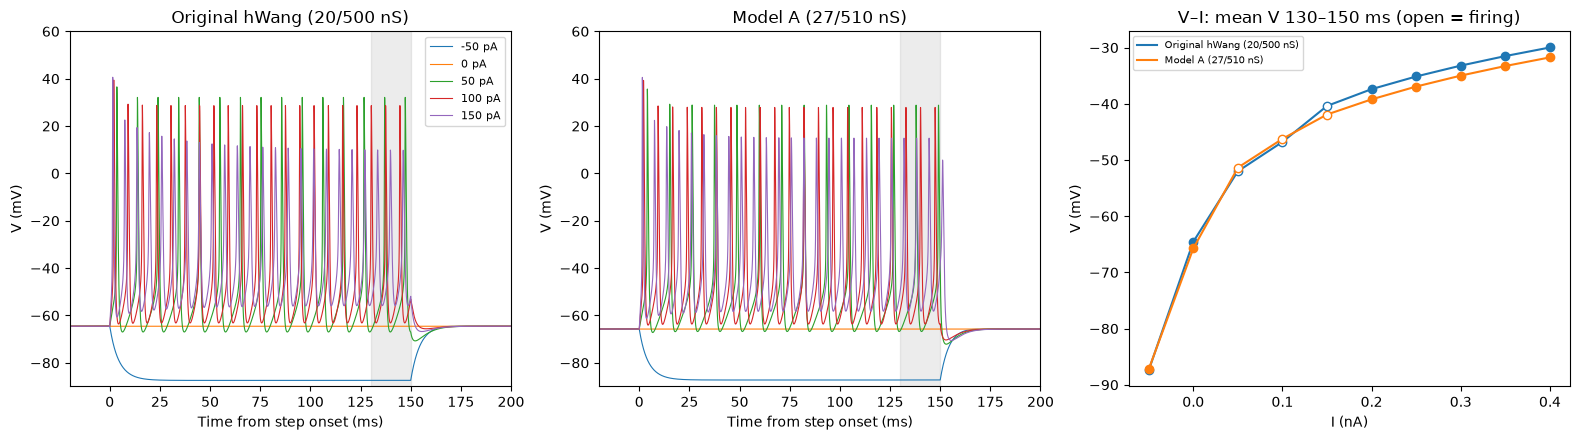

In [21]:
STEP_AMPS = np.arange(-50, 401, 50); STEP_DUR = 150.; W0, W1 = 130., 150.
steps = {(nm, a): run_current(p, [T0, T0+STEP_DUR], [a, 0.], T0+STEP_DUR+50.) for nm, p in MODELS.items() for a in STEP_AMPS}
fig, axes = plt.subplots(1, len(MODELS)+1, figsize=(5.3*(len(MODELS)+1), 4.5))
rows = []
for j, nm in enumerate(MODELS):
    for a in [-50, 0, 50, 100, 150]:
        ev = steps[nm, a]; axes[j].plot(ev['times']-T0, ev['V_m'], lw=.8, label=f'{a} pA')
    axes[j].set(title=nm, xlabel='Time from step onset (ms)', ylabel='V (mV)', xlim=(-20, 200), ylim=(-90, 60))
    axes[j].axvspan(W0, W1, color='gray', alpha=.15)
    vm = []; spk = []
    for a in STEP_AMPS:
        ev = steps[nm, a]; t = ev['times']-T0; V = ev['V_m']; w = (t >= W0) & (t < W1)
        n_win = count_aps(t, V, W0, W1)
        vm.append(V[w].mean()); spk.append(n_win > 0)
        rows.append(dict(Model=nm, I_pA=a, APs=count_aps(t, V, 0., STEP_DUR), APs_in_window=n_win, V_mean_130_150ms=V[w].mean()))
    vm = np.array(vm); spk = np.array(spk); x = STEP_AMPS/1000
    line, = axes[-1].plot(x, vm, '-', label=nm)
    axes[-1].plot(x[~spk], vm[~spk], 'o', color=line.get_color())
    axes[-1].plot(x[spk], vm[spk], 'o', mfc='white', color=line.get_color())
axes[0].legend(fontsize=8)
axes[-1].set(title='V–I: mean V 130–150 ms (open = firing)', xlabel='I (nA)', ylabel='V (mV)'); axes[-1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(results_dir / 'Check_steps.png', dpi=300, bbox_inches='tight')
steps_df = pd.DataFrame(rows); steps_df.to_csv(results_dir / 'Check_steps.csv', index=False)
SUMMARY['APs in 50/100/150 pA steps'] = str([int(steps_df[(steps_df.Model == LOADED_NAME) & (steps_df.I_pA == a)].APs.iloc[0]) for a in [50, 100, 150]])
display(steps_df.pivot(index='I_pA', columns='Model', values=['APs', 'V_mean_130_150ms']).round(2))
plt.show()

### 2.3 Single AP shape
One pulse from rest with both protocols, WT (150 nS) and KO proxy (15 nS). Macica (in vitro, control): peak +28.8 ± 0.4 mV, mean rising slope 171.8 ± 16.6 mV/ms. Max_dVdt is the maximum slope and includes the stimulus, so it is not directly comparable.

In [22]:
rows = []
for nm, p in MODELS.items():
    for amp, dur in [(1400., .25), (2000., .3)]:
        for g in [150., 15.]:
            ev = run_current({**p, 'g_Kv31': g}, [T0, T0+dur], [amp, 0.], T0+30.)
            rows.append(dict(Model=nm, Pulse=f'{amp/1000} nA x {dur} ms', g_Kv31=g, **ap_shape(ev['times'], ev['V_m'], T0)))
ap_df = pd.DataFrame(rows); ap_df.to_csv(results_dir / 'Check_AP_shape.csv', index=False)
s = ap_df[(ap_df.Model == LOADED_NAME) & (ap_df.Pulse == '1.4 nA x 0.25 ms')].set_index('g_Kv31')
SUMMARY['AP peak 1.4 nA (mV)'] = round(float(s.loc[150., 'Peak']), 1)
SUMMARY['Half-width WT -> KO (ms)'] = f"{s.loc[150., 'Half_width']:.3f} -> {s.loc[15., 'Half_width']:.3f}"
display(ap_df.round(3))

,Model,Pulse,g_Kv31,Peak,Time_to_peak,Half_width,Max_dVdt
0,Original hWang (20/500 nS),1.4 nA x 0.25 ms,150.0,42.116,0.400,0.665,828.274
1,Original hWang (20/500 nS),1.4 nA x 0.25 ms,15.0,42.146,0.405,0.900,792.085
2,Original hWang (20/500 nS),2.0 nA x 0.3 ms,150.0,49.414,0.305,0.570,997.411
3,Original hWang (20/500 nS),2.0 nA x 0.3 ms,15.0,49.620,0.305,0.795,964.755
4,Model A (27/510 nS),1.4 nA x 0.25 ms,150.0,42.253,0.395,0.640,882.375
5,Model A (27/510 nS),1.4 nA x 0.25 ms,15.0,42.369,0.400,0.820,858.522
6,Model A (27/510 nS),2.0 nA x 0.3 ms,150.0,49.245,0.305,0.560,1047.412
7,Model A (27/510 nS),2.0 nA x 0.3 ms,15.0,49.500,0.305,0.725,1030.220


### 2.4 Voltage clamp (loaded neuron)
C_m = 1e9 pF, g_Na = 0, V_m set at each segment; holding −40 mV inactivates I_LT. Macica, native I_HT: 10–90% rise time at +60 mV 1.41 ± 0.18 ms; deactivation τ at −40 mV (after 100 ms at +40 mV) 2.35 ± 0.25 ms; activation midpoint 16.6 ± 1.5 mV. I_LT: step from −70 to −20 mV, all models.

,Measure,Model,Macica
0,Rise time 10-90% at +60 mV (ms),0.79,1.41 +- 0.18
1,Deactivation tau at -40 mV (ms),2.57,2.35 +- 0.25
2,Activation midpoint (mV),18.71,16.6 +- 1.5


,Model,I_LT_peak_pA,I_HT_peak_pA
0,Original hWang (20/500 nS),310.6,483.4
1,Model A (27/510 nS),419.3,483.4


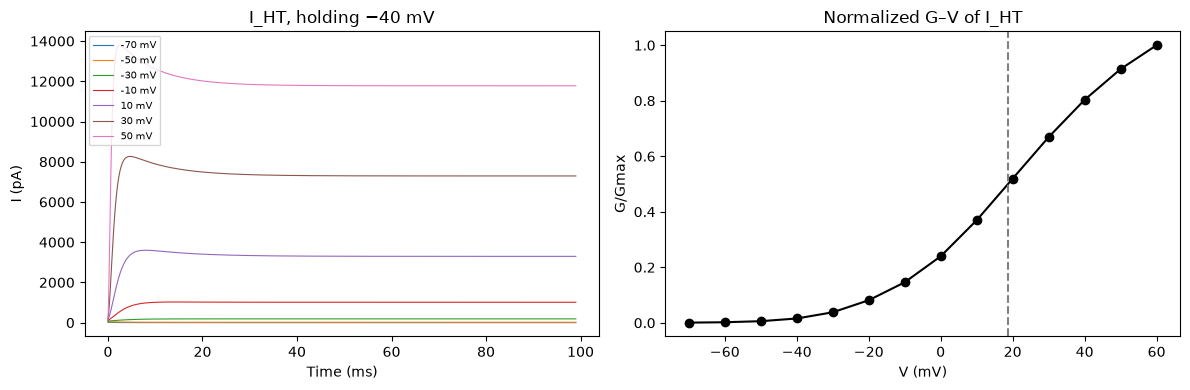

In [23]:
E_K = float(DEFAULTS['E_K'])
V_TEST = np.arange(-70, 61, 10); G = []; traces = {}
for v in V_TEST:
    ev = vclamp(LOADED, [(-40, 300.), (v, 100.)]); s = ev['times'] > 300.
    traces[v] = (ev['times'][s]-300., ev['I_HT'][s]); G.append(ev['I_HT'][s][-1] / (v - E_K))
G = np.array(G) / max(G); v_half = np.interp(.5, G, V_TEST)
t60, i60 = traces[60]; rise = t60[np.argmax(i60 >= .9*i60.max())] - t60[np.argmax(i60 >= .1*i60.max())]
ev = vclamp(LOADED, [(-40, 300.), (40, 100.), (-40, 30.)]); s = ev['times'] > 400.; tt = ev['times'][s]-400.; it = ev['I_HT'][s]
fit = it > .05*it[0]; tau = -1 / np.polyfit(tt[fit], np.log(it[fit]), 1)[0]
kv3 = pd.DataFrame([dict(Measure='Rise time 10-90% at +60 mV (ms)', Model=rise, Macica='1.41 +- 0.18'),
                    dict(Measure='Deactivation tau at -40 mV (ms)', Model=tau, Macica='2.35 +- 0.25'),
                    dict(Measure='Activation midpoint (mV)', Model=v_half, Macica='16.6 +- 1.5')])
kv3.to_csv(results_dir / 'Check_vclamp_Kv3.csv', index=False); display(kv3.round(2))
SUMMARY['Kv3 rise / tau / V1/2'] = f'{rise:.2f} ms / {tau:.2f} ms / {v_half:.1f} mV'
rows = []
for nm, p in MODELS.items():
    ev = vclamp(p, [(-70, 300.), (-20, 100.)]); s = ev['times'] > 300.
    rows.append(dict(Model=nm, I_LT_peak_pA=ev['I_LT'][s].max(), I_HT_peak_pA=ev['I_HT'][s].max()))
lt_df = pd.DataFrame(rows); lt_df.to_csv(results_dir / 'Check_vclamp_LT.csv', index=False); display(lt_df.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for v in V_TEST[::2]: axes[0].plot(*traces[v], lw=.8, label=f'{v} mV')
axes[0].set(title='I_HT, holding −40 mV', xlabel='Time (ms)', ylabel='I (pA)'); axes[0].legend(fontsize=7)
axes[1].plot(V_TEST, G, 'ko-'); axes[1].axvline(v_half, ls='--', c='gray')
axes[1].set(title='Normalized G–V of I_HT', xlabel='V (mV)', ylabel='G/Gmax')
fig.tight_layout(); fig.savefig(results_dir / 'Check_vclamp.png', dpi=300, bbox_inches='tight'); plt.show()

## 3. Figure 1d–f — WT, TEA and knockout
Experimental pulse: 2 nA, 0.3 ms, 100–300 Hz, 100 ms trains. Paper (in vitro): WT follows 300 Hz; TEA normal at 100–200 Hz, progressive loss of full APs at 300 Hz; KO attenuated at 200 Hz, single AP at 300 Hz. TEA 27 nS and KO 15 nS are residual-conductance approximations.
Note: 2 nA × 0.3 ms puts 0.6 pC on 10 pF (about 60 mV of passive depolarization), so a failure cannot fall below −10 mV with this pulse.

,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,WT (150 nS),100,0,100.0,0.305,0.000,49.024
1,WT (150 nS),200,0,100.0,0.319,0.004,45.213
2,WT (150 nS),300,0,100.0,0.353,0.009,41.641
3,TEA (27 nS),100,0,100.0,0.305,0.000,49.485
4,TEA (27 nS),200,0,100.0,0.305,0.001,45.504
5,TEA (27 nS),300,0,100.0,0.382,0.014,35.852
6,KO proxy (15 nS),100,0,100.0,0.305,0.000,49.404
7,KO proxy (15 nS),200,0,100.0,0.314,0.002,44.474
8,KO proxy (15 nS),300,0,100.0,0.397,0.017,32.534


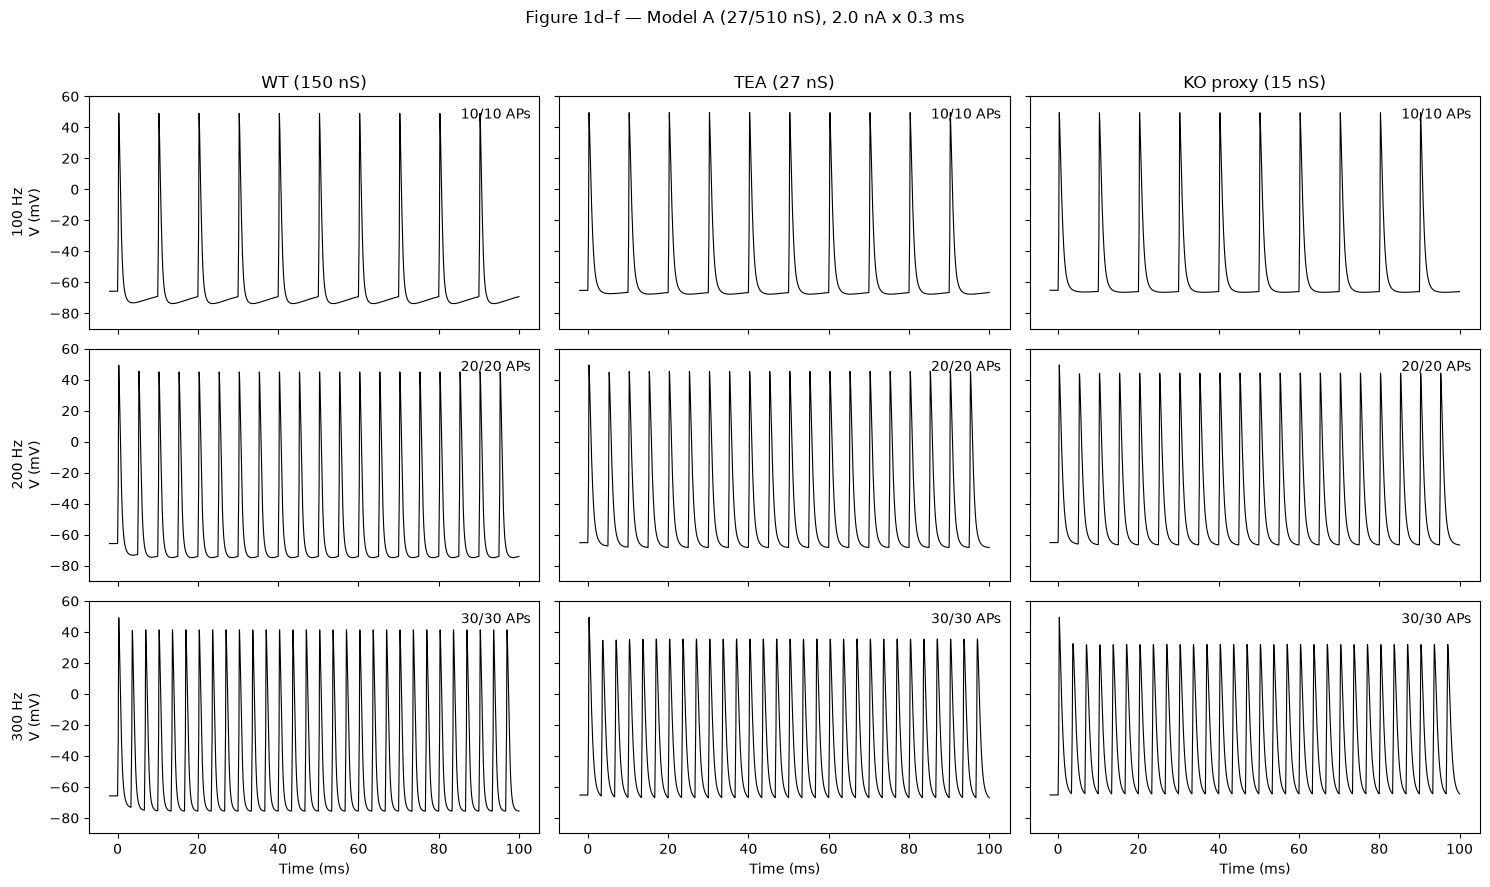

In [24]:
G1 = {'WT (150 nS)': 150., 'TEA (27 nS)': 27., 'KO proxy (15 nS)': 15.}
FIG1_PROTOCOLS = [(2000., .3)]
for amp, dur in FIG1_PROTOCOLS:
    r1 = {(c, f): run_train(g, f, int(f/10), amp=amp, dur=dur) for c, g in G1.items() for f in [100, 200, 300]}
    fig1, axes = plt.subplots(3, 3, figsize=(15, 9), sharex=True, sharey=True)
    for i, f in enumerate([100, 200, 300]):
        for j, c in enumerate(G1):
            ax = axes[i, j]; r = r1[c, f]; t = r['t'] - r['starts'][0]; w = (t >= -2) & (t <= 100)
            ax.plot(t[w], r['V'][w], 'k', lw=.8)
            ax.plot(r['starts'][~r['ok']] - r['starts'][0], np.full(sum(~r['ok']), -85), 'k|', ms=7)
            ax.text(.98, .95, f"{sum(r['ok'])}/{len(r['ok'])} APs", transform=ax.transAxes, ha='right', va='top')
            if i == 0: ax.set_title(c)
            if j == 0: ax.set_ylabel(f'{f} Hz\nV (mV)')
            if i == 2: ax.set_xlabel('Time (ms)')
            ax.set_ylim(-90, 60)
    fig1.suptitle(f'Figure 1d–f — {LOADED_NAME}, {amp/1000} nA x {dur} ms'); fig1.tight_layout(rect=[0, 0, 1, .96])
    save(f'Figure1_{amp:.0f}pA_{dur}ms', fig1, r1)

## 4. Activity A — stimulation protocol and Figure 8
Paper (Macica Fig. 8, in vitro): no failures and invariant delay up to 300 Hz; at 400 Hz the control fires groups of 2–3 APs separated by failures; PMA slightly reduces the failures and the delay (0.99 ± 0.17 → 0.85 ± 0.11 ms).
Conductances: 150 nS control, 100 nS (Fig. 9 reduction, −33%), 83 nS (PMA proxy, −44.8% in vitro). Pulse counts 11, 16, 24, read from the x axes of Fig. 8 (not reported in the paper), same for all conditions.
### A1. Two protocols

,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,Control (150 nS),100,0,100.000,0.404,0.003,43.257
1,Control (150 nS),300,0,100.000,0.540,0.039,39.620
2,Control (150 nS),400,8,66.667,0.627,0.146,32.022
3,Reduced (100 nS),100,0,100.000,0.404,0.003,43.249
4,Reduced (100 nS),300,0,100.000,0.515,0.031,39.024
5,Reduced (100 nS),400,7,70.833,0.711,0.184,23.138
6,PMA proxy (83 nS),100,0,100.000,0.404,0.003,43.220
7,PMA proxy (83 nS),300,0,100.000,0.511,0.030,38.420
8,PMA proxy (83 nS),400,7,70.833,0.752,0.219,19.610


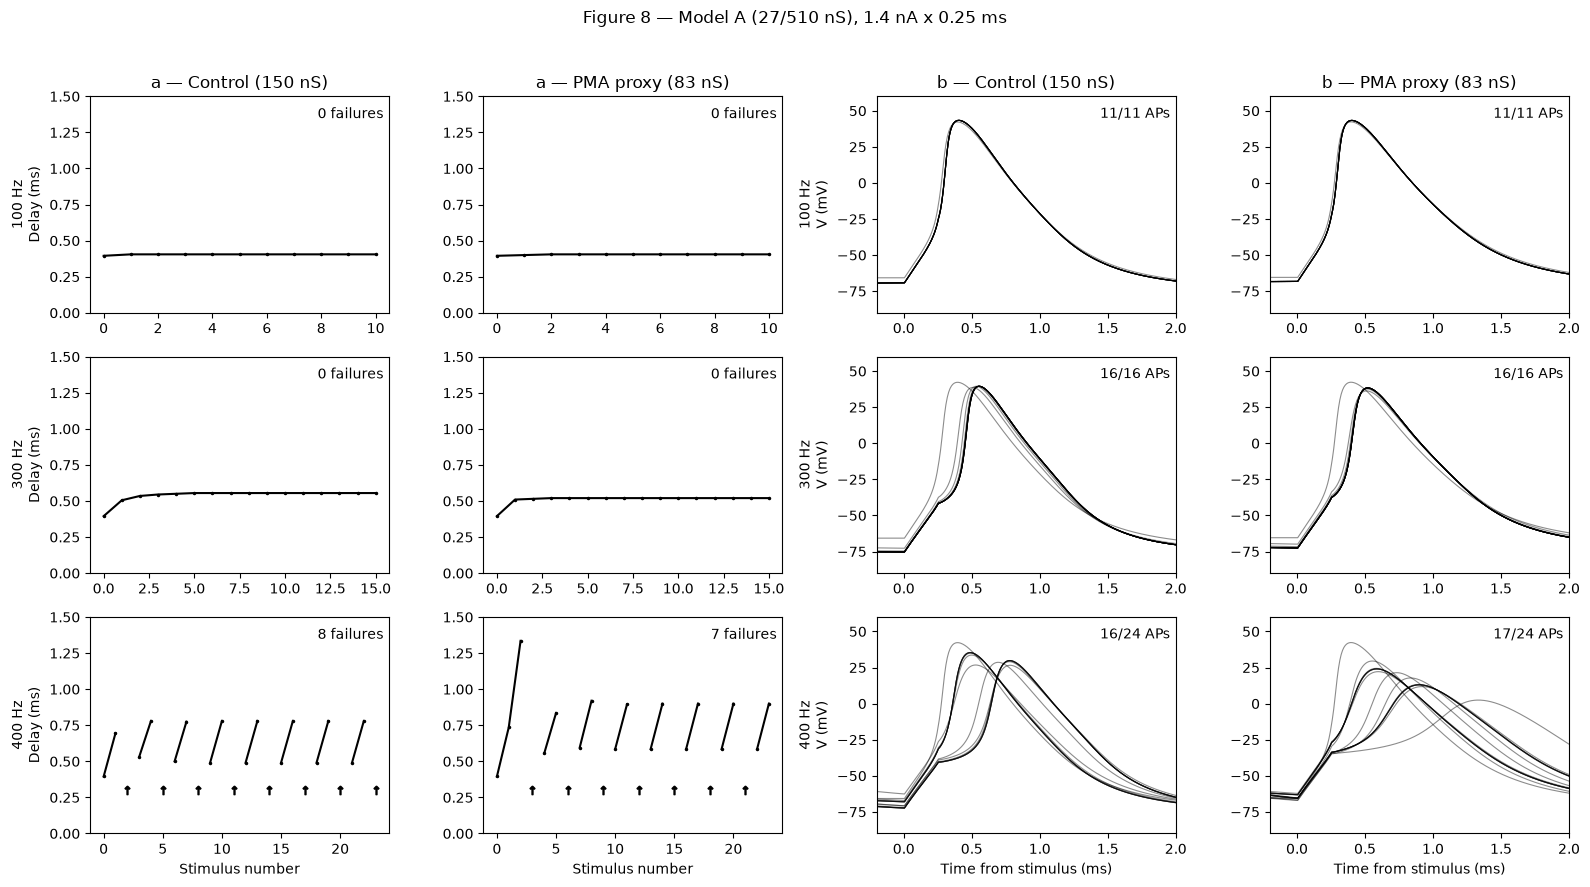

,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,Control (150 nS),100,0,100.0,0.305,0.000,49.022
1,Control (150 nS),300,0,100.0,0.352,0.012,41.858
2,Control (150 nS),400,0,100.0,0.392,0.018,36.404
3,Reduced (100 nS),100,0,100.0,0.305,0.000,49.259
4,Reduced (100 nS),300,0,100.0,0.352,0.012,41.628
5,Reduced (100 nS),400,0,100.0,0.406,0.021,33.536
6,PMA proxy (83 nS),100,0,100.0,0.305,0.000,49.341
7,PMA proxy (83 nS),300,0,100.0,0.352,0.012,41.289
8,PMA proxy (83 nS),400,0,100.0,0.416,0.023,31.274


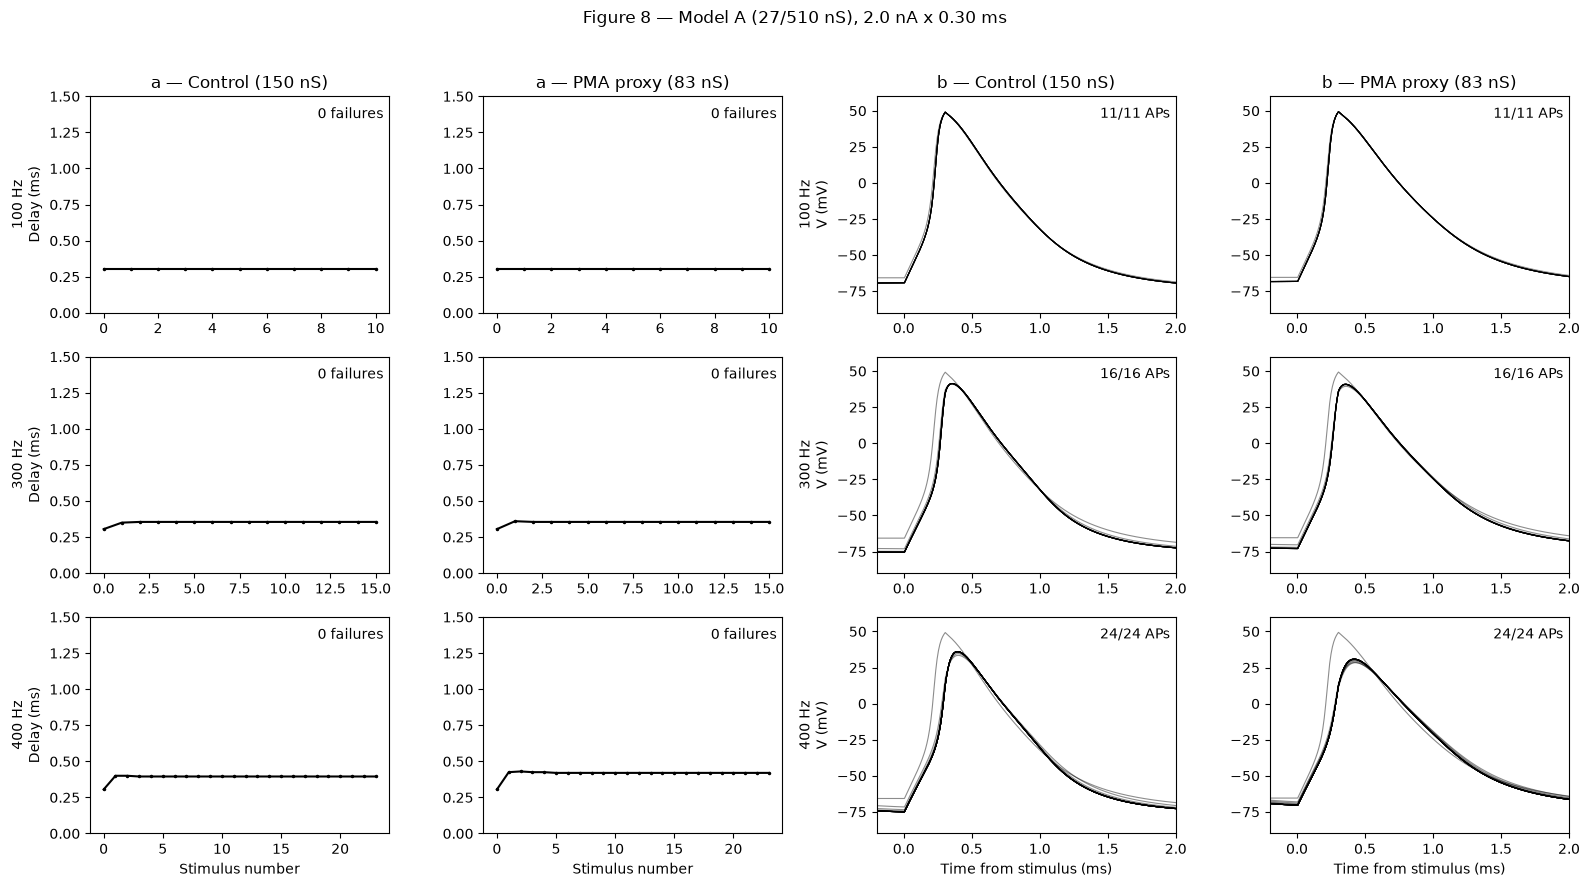

In [25]:
n8 = {100: 11, 300: 16, 400: 24}
A_PROTOCOLS = {'1.4 nA x 0.25 ms': (1400., .25), '2.0 nA x 0.30 ms': (2000., .3)}
A_G = {'Control (150 nS)': 150., 'Reduced (100 nS)': 100., 'PMA proxy (83 nS)': 83.}
rA = {}
for pname, (amp, dur) in A_PROTOCOLS.items():
    rA[pname] = {(c, f): run_train(g, f, n8[f], amp=amp, dur=dur) for c, g in A_G.items() for f in n8}
    figA = combined_plot(rA[pname], ['Control (150 nS)', 'PMA proxy (83 nS)'], list(n8), list(n8), f'Figure 8 — {LOADED_NAME}, {pname}')
    save('ActivityA1_' + pname.replace(' ', '').replace('.', 'p'), figA, rA[pname])

### A2. Amplitude and duration at 400 Hz
Paper pattern = failures in the control, fewer failures with PMA, shorter and less variable delay with PMA.

,Amplitude_pA,Duration_ms,Charge_pC,Ctrl_failures,Ctrl_delay,Ctrl_jitter,PMA_failures,PMA_delay,PMA_jitter,Ctrl_fails,Fewer_with_PMA,Better_timing_PMA,Paper_pattern
0,1400,0.25,0.350,8,0.627,0.146,7,0.752,0.219,True,True,False,False
1,1500,0.25,0.375,4,0.680,0.158,5,0.772,0.194,True,False,False,False
2,1600,0.25,0.400,0,0.589,0.049,1,0.743,0.099,False,False,False,False
3,1700,0.25,0.425,0,0.503,0.031,0,0.570,0.045,False,False,False,False
4,1800,0.25,0.450,0,0.460,0.025,0,0.510,0.035,False,False,False,False
5,1900,0.25,0.475,0,0.431,0.021,0,0.475,0.031,False,False,False,False
6,2000,0.25,0.500,0,0.412,0.019,0,0.448,0.027,False,False,False,False
7,1400,0.30,0.420,0,0.592,0.044,0,0.755,0.093,False,False,False,False
8,1500,0.30,0.450,0,0.519,0.031,0,0.585,0.045,False,False,False,False
9,1600,0.30,0.480,0,0.480,0.027,0,0.528,0.037,False,False,False,False


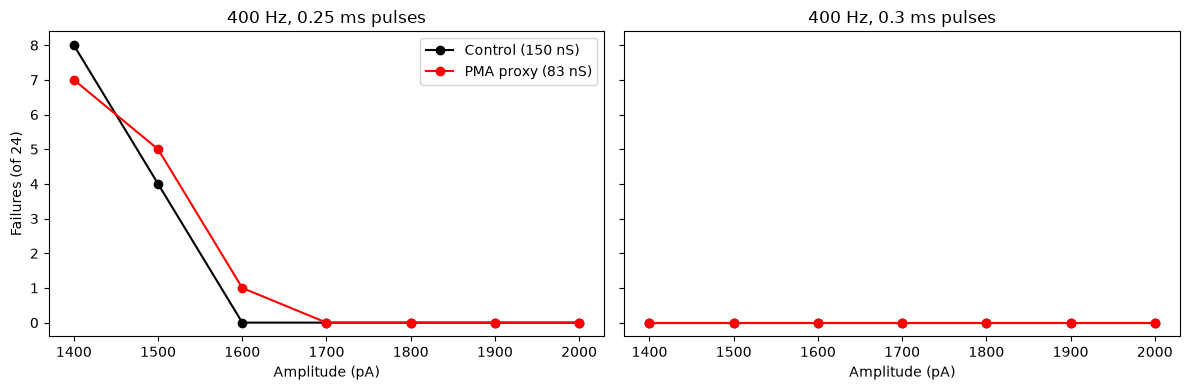

In [26]:
def a400(amp, dur):
    row = dict(Amplitude_pA=round(amp), Duration_ms=dur, Charge_pC=round(amp*dur/1000, 3))
    for tag, g in [('Ctrl', 150.), ('PMA', 83.)]:
        r = run_train(g, 400, n8[400], amp=float(amp), dur=dur); d = r['delay'][r['ok']]
        row.update({tag+'_failures': int(sum(~r['ok'])), tag+'_delay': np.mean(d) if len(d) else np.nan, tag+'_jitter': np.std(d) if len(d) else np.nan})
    row['Ctrl_fails'] = row['Ctrl_failures'] > 0
    row['Fewer_with_PMA'] = row['PMA_failures'] < row['Ctrl_failures']
    row['Better_timing_PMA'] = (row['PMA_delay'] < row['Ctrl_delay']) & (row['PMA_jitter'] < row['Ctrl_jitter'])
    row['Paper_pattern'] = row['Ctrl_fails'] & row['Fewer_with_PMA'] & row['Better_timing_PMA']
    return row

A_AMPS = np.arange(1400, 2001, 100); A_DURS = [.25, .3]
grid = pd.DataFrame([a400(amp, dur) for dur in A_DURS for amp in A_AMPS])
grid.to_csv(results_dir / 'ActivityA2_grid_400Hz.csv', index=False); display(grid.round(3))
fig, axes = plt.subplots(1, len(A_DURS), figsize=(12, 4), sharey=True)
for ax, dur in zip(axes, A_DURS):
    s = grid[grid.Duration_ms == dur]
    ax.plot(s.Amplitude_pA, s.Ctrl_failures, 'ko-', label='Control (150 nS)'); ax.plot(s.Amplitude_pA, s.PMA_failures, 'ro-', label='PMA proxy (83 nS)')
    ax.set(title=f'400 Hz, {dur} ms pulses', xlabel='Amplitude (pA)')
axes[0].set_ylabel(f'Failures (of {n8[400]})'); axes[0].legend()
fig.tight_layout(); fig.savefig(results_dir / 'ActivityA2_grid_400Hz.png', dpi=300, bbox_inches='tight'); plt.show()

### A2b. Other pulse durations at 400 Hz
Same test with 0.1, 0.2, 0.3 and 0.5 ms pulses, with amplitudes chosen to cover charges of 0.28–0.40 pC (where failures appear).

In [27]:
A2B_DURS = [.1, .2, .3, .5]; A2B_Q = [.28, .30, .32, .34, .36, .38, .40]
grid_b = pd.DataFrame([a400(q/dur*1000, dur) for dur in A2B_DURS for q in A2B_Q])
grid_b.to_csv(results_dir / 'ActivityA2b_durations_400Hz.csv', index=False); display(grid_b.round(3))
print('Combinations with the paper pattern:', int(grid_b.Paper_pattern.sum()), 'of', len(grid_b))

,Amplitude_pA,Duration_ms,Charge_pC,Ctrl_failures,Ctrl_delay,Ctrl_jitter,PMA_failures,PMA_delay,PMA_jitter,Ctrl_fails,Fewer_with_PMA,Better_timing_PMA,Paper_pattern
0,2800,0.1,0.28,12,0.432,0.028,11,0.581,0.264,True,True,False,False
1,3000,0.1,0.30,9,0.610,0.477,8,0.781,0.339,True,True,False,False
2,3200,0.1,0.32,8,0.565,0.190,7,0.645,0.221,True,True,False,False
3,3400,0.1,0.34,5,0.564,0.178,6,0.674,0.199,True,False,False,False
4,3600,0.1,0.36,0,0.536,0.060,2,0.655,0.135,False,False,False,False
5,3800,0.1,0.38,0,0.417,0.031,0,0.455,0.039,False,False,False,False
6,4000,0.1,0.40,0,0.366,0.022,0,0.404,0.030,False,False,False,False
7,1400,0.2,0.28,12,0.529,0.034,12,0.583,0.049,True,False,False,False
8,1500,0.2,0.30,12,0.492,0.031,11,0.633,0.163,True,True,False,False
9,1600,0.2,0.32,9,0.702,0.333,8,0.776,0.267,True,True,False,False


Combinations with the paper pattern: 0 of 28


### A3. Critical frequency (350–450 Hz, 10 Hz steps, 100 ms trains as in Fig. 9)
Critical frequency = first frequency with failures. Set `A_PROTOCOL` to the protocol chosen after A1–A2.

Critical frequency (first frequency with failures): {'Control (150 nS)': 350, 'Reduced (100 nS)': 370, 'PMA proxy (83 nS)': 370}


,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,Control (150 nS),350,2,94.286,0.757,0.145,33.051
1,Control (150 nS),360,5,86.111,0.729,0.194,33.811
2,Control (150 nS),370,7,81.081,0.749,0.276,32.845
3,Control (150 nS),380,9,76.316,0.696,0.202,33.263
4,Control (150 nS),390,10,74.359,0.742,0.421,30.012
5,Control (150 nS),400,13,67.500,0.625,0.145,32.376
6,Control (150 nS),410,13,68.293,0.681,0.195,32.157
7,Control (150 nS),420,14,66.667,0.805,0.351,30.117
8,Control (150 nS),430,17,60.465,0.758,0.350,28.399
9,Control (150 nS),440,21,52.273,0.564,0.094,26.581


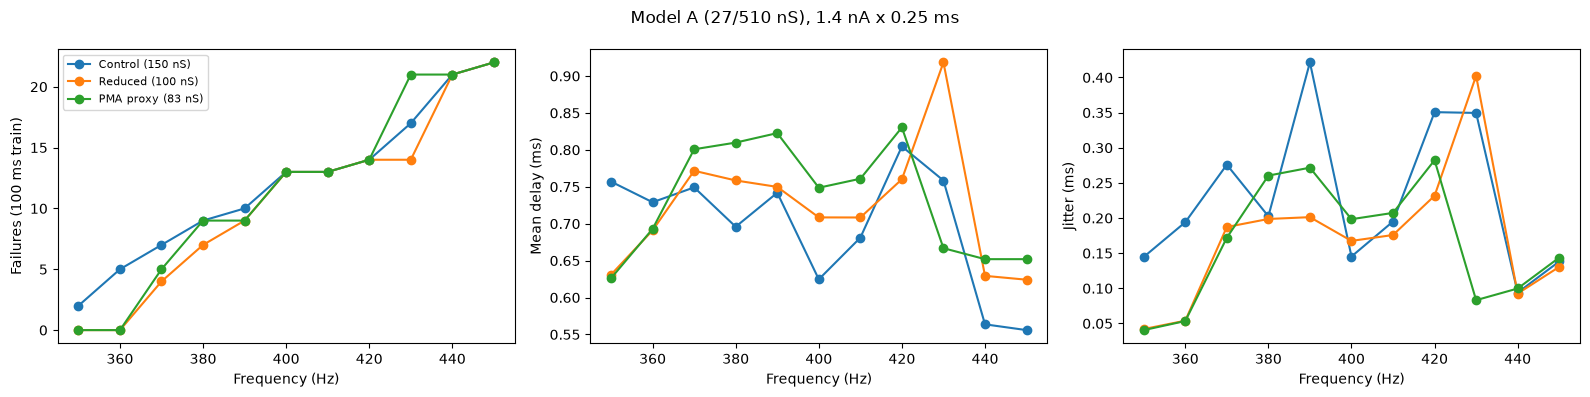

In [28]:
A_PROTOCOL = (1400., .25)
FREQS = np.arange(350, 451, 10)
rcrit = {(c, int(f)): run_train(g, int(f), int(f/10), amp=A_PROTOCOL[0], dur=A_PROTOCOL[1]) for c, g in A_G.items() for f in FREQS}
crit_df = metrics(rcrit); crit_df.to_csv(results_dir / 'ActivityA3_critical_frequency.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for c in A_G:
    s = crit_df[crit_df.Condition == c]
    axes[0].plot(s.Frequency, s.Failures, 'o-', label=c); axes[1].plot(s.Frequency, s.Mean_delay, 'o-'); axes[2].plot(s.Frequency, s.Jitter, 'o-')
axes[0].set(xlabel='Frequency (Hz)', ylabel='Failures (100 ms train)'); axes[0].legend(fontsize=8)
axes[1].set(xlabel='Frequency (Hz)', ylabel='Mean delay (ms)'); axes[2].set(xlabel='Frequency (Hz)', ylabel='Jitter (ms)')
fig.suptitle(f'{LOADED_NAME}, {A_PROTOCOL[0]/1000} nA x {A_PROTOCOL[1]} ms'); fig.tight_layout()
fig.savefig(results_dir / 'ActivityA3_critical_frequency.png', dpi=300, bbox_inches='tight')
crit = {c: next((int(f) for f in FREQS if sum(~rcrit[c, int(f)]['ok']) > 0), None) for c in A_G}
print('Critical frequency (first frequency with failures):', crit)
SUMMARY['Critical frequency ctrl / 100 / 83 nS (Hz)'] = f"{crit['Control (150 nS)']} / {crit['Reduced (100 nS)']} / {crit['PMA proxy (83 nS)']}"
display(crit_df.round(3)); plt.show()

### A4. Figure 8 at an intermediate frequency
In the model the PMA benefit appears just above the control critical frequency. `F_INT` replaces 400 Hz (default 360 Hz, the "intermediate frequency equivalent"); choose it from A3.

,Condition,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak
0,Control (150 nS),100,0,100.0,0.404,0.003,43.257
1,Control (150 nS),300,0,100.0,0.540,0.039,39.620
2,Control (150 nS),360,3,87.5,0.733,0.203,33.840
3,Reduced (100 nS),100,0,100.0,0.404,0.003,43.249
4,Reduced (100 nS),300,0,100.0,0.515,0.031,39.024
5,Reduced (100 nS),360,0,100.0,0.683,0.065,30.207
6,PMA proxy (83 nS),100,0,100.0,0.404,0.003,43.220
7,PMA proxy (83 nS),300,0,100.0,0.511,0.030,38.420
8,PMA proxy (83 nS),360,0,100.0,0.686,0.064,27.339


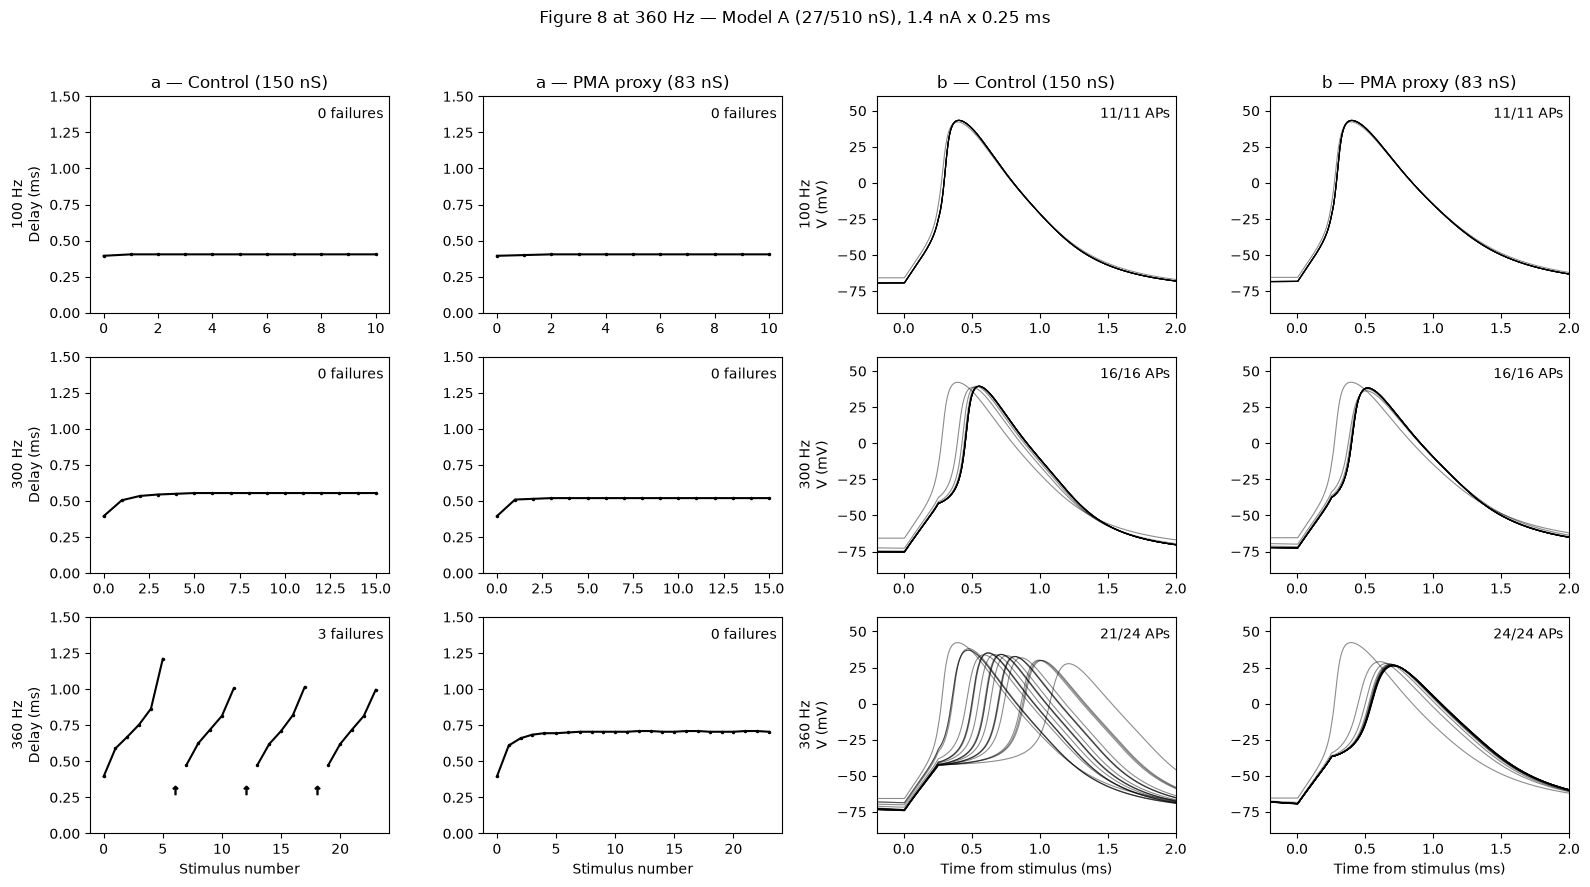

In [29]:
F_INT = 360
n8i = {100: 11, 300: 16, F_INT: 24}
r8i = {(c, f): run_train(g, f, n8i[f], amp=A_PROTOCOL[0], dur=A_PROTOCOL[1]) for c, g in A_G.items() for f in n8i}
fig8i = combined_plot(r8i, ['Control (150 nS)', 'PMA proxy (83 nS)'], list(n8i), list(n8i), f'Figure 8 at {F_INT} Hz — {LOADED_NAME}, {A_PROTOCOL[0]/1000} nA x {A_PROTOCOL[1]} ms')
df8i = save(f'ActivityA4_Fig8_{F_INT}Hz', fig8i, r8i)

## 5. Summary
Key numbers for the loaded neuron, saved to `summary.csv` to compare different neurons.

In [30]:
summary = pd.Series(SUMMARY, name=LOADED_NAME)
summary.to_csv(results_dir / 'summary.csv'); display(summary.to_frame())

,Model A (27/510 nS)
Fig9 failures Control (150 nS) (300/350/360/410),"[0, 2, 5, 13]"
Fig9 failures Reduced (100 nS) (300/350/360/410),"[0, 0, 0, 13]"
Rest (mV),-65.74
APs in 50/100/150 pA steps,"[14, 21, 24]"
AP peak 1.4 nA (mV),42.3
Half-width WT -> KO (ms),0.640 -> 0.820
Kv3 rise / tau / V1/2,0.79 ms / 2.57 ms / 18.7 mV
Critical frequency ctrl / 100 / 83 nS (Hz),350 / 370 / 370
